# E-role comparison

Test whether E players with Ds/Dd offer a different profile from the remaining E players. This describes current eligible players using **2025–26** performance; it does not establish that excluding E from a formation improves the whole lineup.

## 1. Query design

- Select one performance season; current roles and team come from the configured eligibility snapshot (2026–27).
- Apply **rated matches / 38 ≥ 0.30** before comparing groups: at least 12 rated matches. This is observed coverage, an availability proxy, not injury or appearance probability.
- **Defensive E:** E and at least one of Ds/Dd. **Other E:** E without Ds/Dd (including C/W and E-only). Ds/Dd takes precedence for mixed roles; nobody enters both groups.
- Mean FV and upside (within-player FV P90) use valid FV observations.
- Goals and assists per match use rated observations where that event is known; missing values are not zero.
- Bonus rate: fraction of observations with a goal, scored penalty, or assist, among observations where all three are known. No event values are added to published FV.
- Card rate: yellow or red among rated observations with both flags known; lower is better.
- **Consistency = fraction of valid FV ≥ 6**: frequency of satisfactory returns, not low variance.

The filter uses rated matches, so inspect FV and event sample sizes separately. Fixture coverage does not guarantee every player/event observation is present. Players below the filter, including newcomers without sufficient history, are excluded from this comparison only.

In [5]:
%matplotlib inline
from project.analysis.queries import connect_database, fetch_e_comparison, E_COMPARISON_QUERY
from project.analysis.e_comparison import plot_e_comparison
import matplotlib.pyplot as plt
from IPython.display import display

PERFORMANCE_SEASON = 2023
MIN_COVERAGE = 0.30
print(E_COMPARISON_QUERY)
print({"season": PERFORMANCE_SEASON, "min_fraction": MIN_COVERAGE})


    SELECT player_id, source_id, player_name, current_team, roles,
           eligibility_season, performance_season,
           CASE WHEN roles && ARRAY['Ds', 'Dd']::text[]
                THEN 'Defensive E' ELSE 'Other E' END AS role_group,
           mean_fv,
           rated_season_fraction AS availability,
           source_goals_per_rated_match AS goals_per_match,
           assists_per_rated_match AS assists_per_match,
           bonus_rate, card_rate,
           fv_ge6_rate AS consistency,
           fv_p90 AS upside,
           rated_matches, fv_matches, fv_season_fraction,
           goal_sample, assist_sample, bonus_sample, card_sample,
           coverage_status, imported_fixtures, complete_matchdays, evidence_status
    FROM player_season_metrics
    WHERE performance_season = :season
      AND rated_season_fraction >= :min_fraction
      AND 'E' = ANY(roles)
    ORDER BY role_group, mean_fv DESC NULLS LAST, player_id, source_id

{'season': 2023, 'min_fraction': 0.3}


In [6]:
engine = connect_database()
try:
    players = fetch_e_comparison(
        engine, PERFORMANCE_SEASON,
        min_rated_season_fraction=MIN_COVERAGE,
    )
finally:
    engine.dispose()

display(players.groupby(["role_group", "coverage_status"]).size().rename("players").to_frame())
display(players)

,,players
role_group,coverage_status,
Defensive E,complete,31
Other E,complete,5


,player_id,source_id,player_name,current_team,roles,eligibility_season,performance_season,role_group,mean_fv,availability,...,fv_matches,fv_season_fraction,goal_sample,assist_sample,bonus_sample,card_sample,coverage_status,imported_fixtures,complete_matchdays,evidence_status
0,238,1,De Silvestri,Bologna,"[Dd, E]",2026,2023,Defensive E,6.666667,0.315789,...,12,0.315789,12,12,12,12,complete,380,38,limited_sample
1,108,1,Zortea,Bologna,"[Dd, E]",2026,2023,Defensive E,6.631579,0.500000,...,19,0.500000,19,19,19,19,complete,380,38,larger_sample
2,124,1,Bellanova,Atalanta,"[Dd, E]",2026,2023,Defensive E,6.347222,0.947368,...,36,0.947368,36,36,36,36,complete,380,38,larger_sample
3,98,1,Spinazzola,Napoli,"[Ds, E]",2026,2023,Defensive E,6.304348,0.605263,...,23,0.605263,23,23,23,23,complete,380,38,larger_sample
4,135,1,Carlos Augusto,Inter,"[B, Ds, E]",2026,2023,Defensive E,6.214286,0.921053,...,35,0.921053,35,35,35,35,complete,380,38,larger_sample
5,80,1,Di Lorenzo,Napoli,"[Dd, E]",2026,2023,Defensive E,6.208333,0.947368,...,36,0.947368,36,36,36,36,complete,380,38,larger_sample
6,165,1,Rodriguez R.,Torino,"[B, Ds, E]",2026,2023,Defensive E,6.171429,0.921053,...,35,0.921053,35,35,35,35,complete,380,38,larger_sample
7,94,1,Cambiaso,Juventus,"[Dd, Ds, E]",2026,2023,Defensive E,6.117647,0.894737,...,34,0.894737,34,34,34,34,complete,380,38,larger_sample
8,229,1,Biraghi,Torino,"[B, Ds, E]",2026,2023,Defensive E,6.107143,0.736842,...,28,0.736842,28,28,28,28,complete,380,38,larger_sample
9,90,1,Kamara H.,Udinese,"[Ds, E]",2026,2023,Defensive E,6.096774,0.815789,...,31,0.815789,31,31,31,31,complete,380,38,larger_sample


## 2. Compare profiles with Matplotlib

Each player has equal weight: the raw table averages **player-level metrics**, rather than pooling matches. Group upside is the average of players’ P90s, not the P90 of pooled FV.

For the radar, first rank each metric across all retained E players, then average those ranks within each group. Ties receive the average rank; the midpoint percentile formula is `100 × (rank − 0.5) / number of known values`. Card ranks are reversed, so outward always means better. Missing metrics are omitted individually and the contributing player counts are displayed.

These are relative ranks within this filtered pool. Changing the season or filter changes the reference pool. Polygon area is not an overall score, and correlated axes (goals, bonuses, FV) are not independent evidence. Read the raw table alongside the chart.

Raw averages (rates are fractions from 0 to 1):


,mean_fv,availability,goals_per_match,assists_per_match,bonus_rate,card_rate,consistency,upside
role_group,,,,,,,,
Defensive E,5.961,0.641,0.026,0.067,0.089,0.163,0.619,6.735
Other E,6.346,0.616,0.070,0.089,0.152,0.082,0.712,8.200


Players contributing to each metric:


,mean_fv,availability,goals_per_match,assists_per_match,bonus_rate,card_rate,consistency,upside
role_group,,,,,,,,
Defensive E,31,31,31,31,31,31,31,31
Other E,5,5,5,5,5,5,5,5


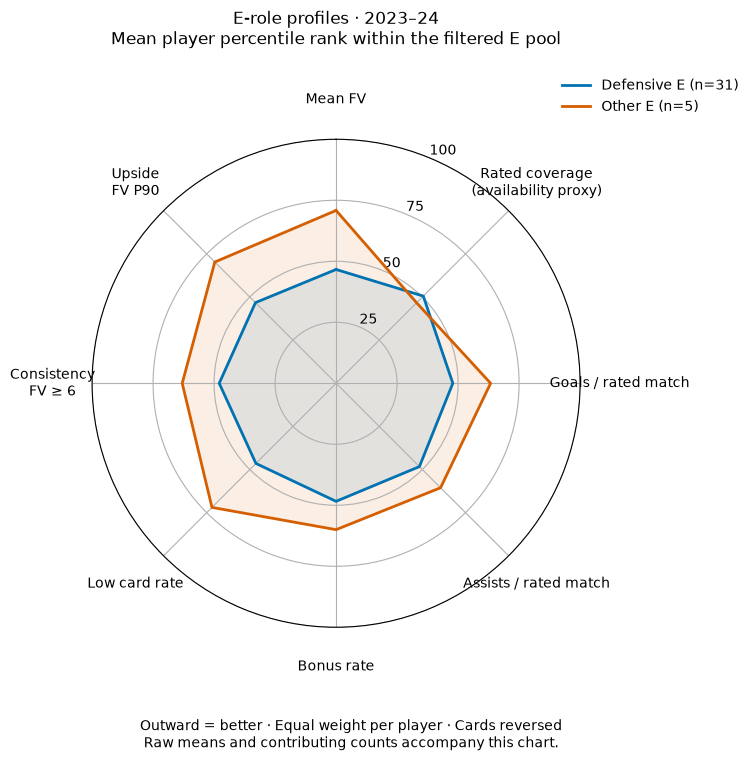

In [7]:
fig, raw_means, contributing_players = plot_e_comparison(players)
print("Raw averages (rates are fractions from 0 to 1):")
display(raw_means.round(3))
print("Players contributing to each metric:")
display(contributing_players)
plt.show()

## 3. Interpretation

Check the direction and size of differences in the raw table, alongside group sizes and sample coverage. Repeat with `PERFORMANCE_SEASON = 2024` or `2023` to assess whether the pattern persists; run each season separately.

To evaluate a formation without E, the next comparison must include the players who would replace E slots in legal alternative formations, ideally with comparable auction costs. An average group profile can hide the best individual targets.

### Initial result: 2025–26

The filter retains **41 Defensive E** and **7 Other E** players, with complete fixture coverage and non-missing metrics for every retained player. Other E has favorable raw averages on all eight axes (mean FV 6.324 vs 6.019; bonus rate 15.1% vs 9.3%; card rate 10.3% vs 14.7%). These descriptive results do not support a blanket claim that E options perform poorly.

Assist rates illustrate why the raw table matters: Other E has higher mean assists per rated match (0.096 vs 0.060), but a lower average percentile rank. Ranking reduces the influence of exceptionally high values, so ordering can differ from raw averages. The seven-player group and current-roster selection limit generalization.
